In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings("ignore")

plt.style.use("ggplot")

In [2]:
df = pd.read_csv("../data/Mall_Customers.csv")

df.rename(columns={
    "Genre":"Gender",
    "Annual Income (k$)": "Income",
    "Spending Score (1-100)": "Score"
}, inplace=True)

df.head()

,CustomerID,Gender,Age,Income,Score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

Shape: (200, 5)

Columns:
Index(['CustomerID', 'Gender', 'Age', 'Income', 'Score'], dtype='str')

Data Types:
CustomerID    int64
Gender          str
Age           int64
Income        int64
Score         int64
dtype: object


In [4]:
df.isnull().sum()

CustomerID    0
Gender        0
Age           0
Income        0
Score         0
dtype: int64

In [5]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [6]:
df.drop_duplicates(inplace=True)

print(df.shape)

(200, 5)


In [7]:
df.describe()

,CustomerID,Age,Income,Score
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


**Encoding**

In [14]:
encoder = LabelEncoder()

df["Gender"] = encoder.fit_transform(df["Gender"])

df.head()

,CustomerID,Gender,Age,Income,Score
0,1,1,19,15,39
1,2,1,21,15,81
2,3,0,20,16,6
3,4,0,23,16,77
4,5,0,31,17,40


**Male : 1 and Female: 0**

In [16]:
df["Gender"].value_counts()

Gender
0    112
1     88
Name: count, dtype: int64

**Feature Selection**

In [17]:
features = df[["Gender","Age","Income","Score"]]

features.head()

,Gender,Age,Income,Score
0,1,19,15,39
1,1,21,15,81
2,0,20,16,6
3,0,23,16,77
4,0,31,17,40


**Outlier Detection**

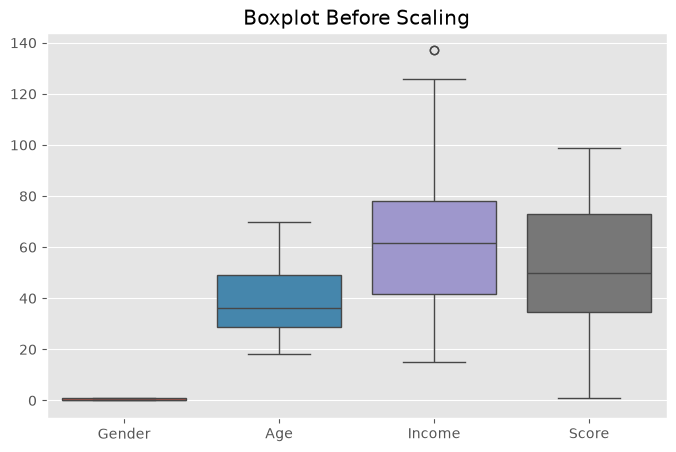

In [18]:
plt.figure(figsize=(8,5))

sns.boxplot(data=features)

plt.title("Boxplot Before Scaling")

plt.show()

In [19]:
Q1 = features.quantile(0.25)

Q3 = features.quantile(0.75)

IQR = Q3 - Q1

print(IQR)

Gender     1.00
Age       20.25
Income    36.50
Score     38.25
dtype: float64


In [20]:
outliers = ((features < (Q1 - 1.5 * IQR)) |
            (features > (Q3 + 1.5 * IQR)))

outliers.sum()

Gender    0
Age       0
Income    2
Score     0
dtype: int64

In [21]:
clean_df = features[
    ~((features < (Q1 - 1.5 * IQR)) |
      (features > (Q3 + 1.5 * IQR))).any(axis=1)
]

clean_df.shape

(198, 4)

In [22]:
print("Original Dataset:", features.shape)

print("Clean Dataset:", clean_df.shape)

Original Dataset: (200, 4)
Clean Dataset: (198, 4)


**Scaling**

In [23]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(clean_df)

In [24]:
scaled_df = pd.DataFrame(
    scaled_data,
    columns=clean_df.columns
)

scaled_df.head()

,Gender,Age,Income,Score
0,1.141195,-1.425414,-1.779171,-0.435989
1,1.141195,-1.282367,-1.779171,1.199413
2,-0.876275,-1.353890,-1.739447,-1.720949
3,-0.876275,-1.139319,-1.739447,1.043661
4,-0.876275,-0.567131,-1.699723,-0.397051


In [25]:
scaled_df.mean()

Gender   -4.485750e-17
Age       1.435440e-16
Income    0.000000e+00
Score     1.104616e-16
dtype: float64

In [26]:
scaled_df.std()

Gender    1.002535
Age       1.002535
Income    1.002535
Score     1.002535
dtype: float64

**Visualization**

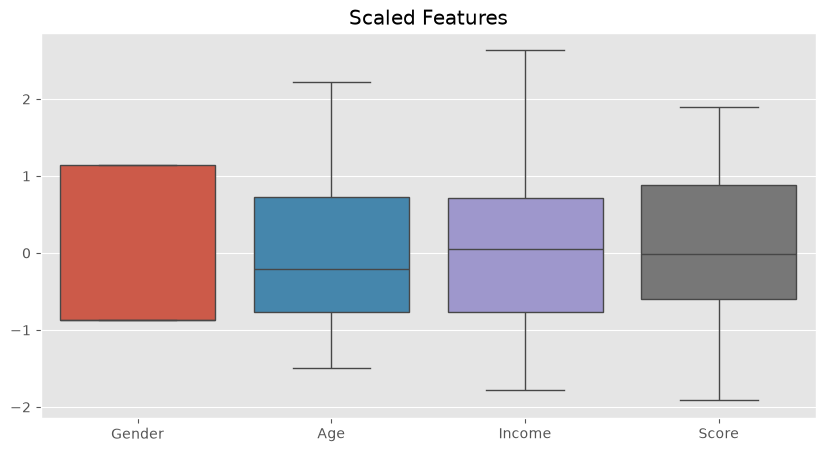

In [27]:
plt.figure(figsize=(10,5))

sns.boxplot(data=scaled_df)

plt.title("Scaled Features")

plt.show()

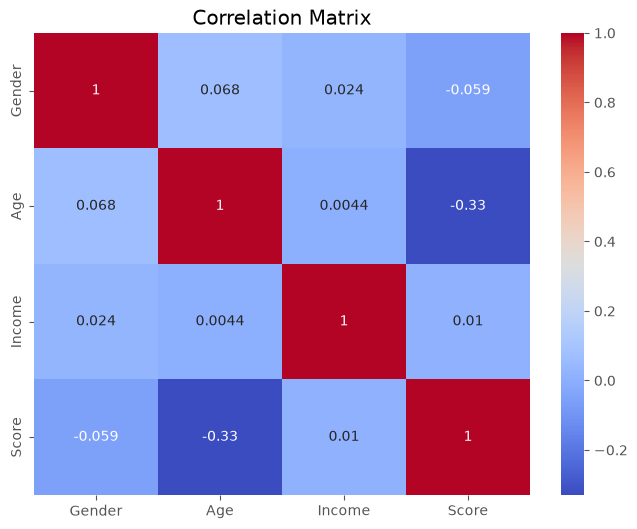

In [28]:
plt.figure(figsize=(8,6))

sns.heatmap(
    scaled_df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()

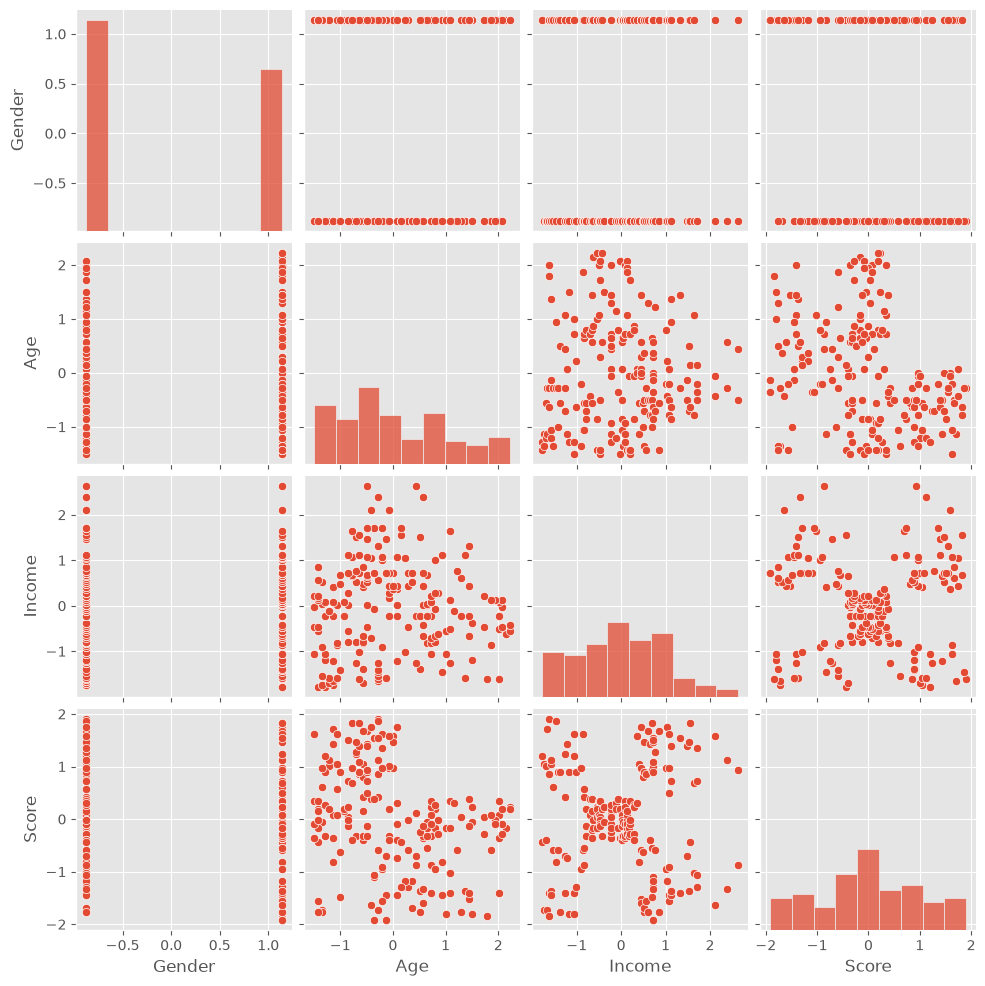

In [29]:
sns.pairplot(scaled_df)

plt.show()

**Distribution After Scaling**

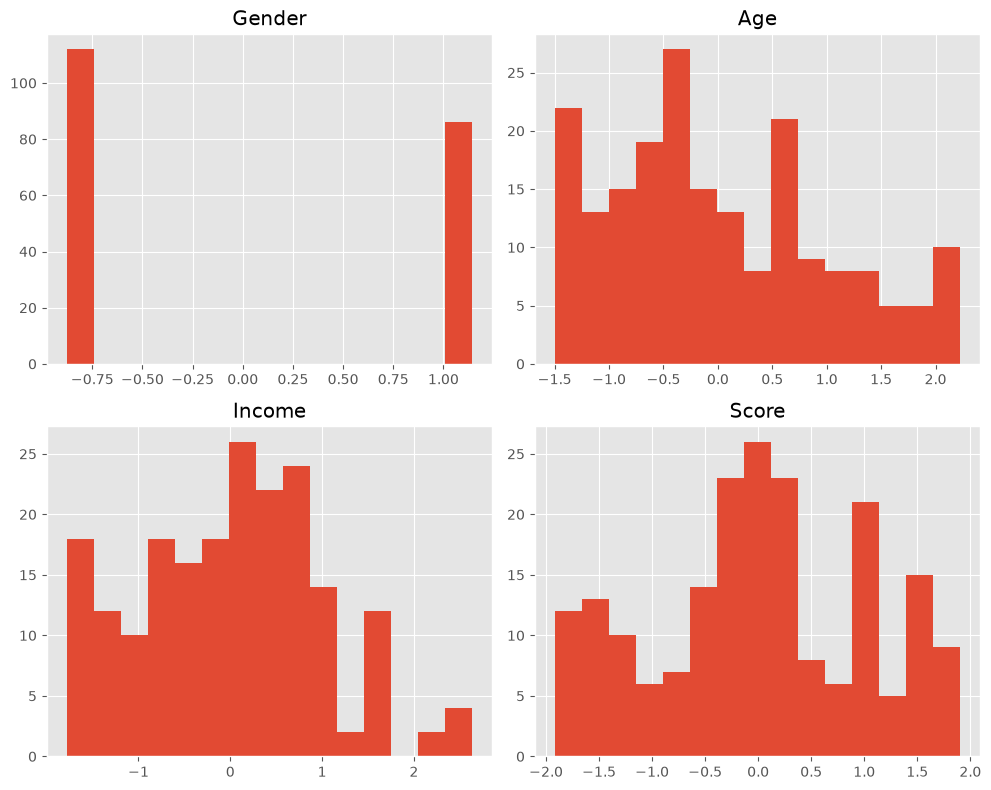

In [30]:
scaled_df.hist(
    figsize=(10,8),
    bins=15
)

plt.tight_layout()

plt.show()

**Save Processed Dataset**

In [31]:
scaled_df.to_csv(
    "../data/processed_customers.csv",
    index=False
)

print("Processed dataset saved successfully!")

Processed dataset saved successfully!


**Save Clean Dataset**

In [32]:
clean_df.to_csv(
    "../data/clean_customers.csv",
    index=False
)

print("Clean dataset saved successfully!")

Clean dataset saved successfully!


In [33]:
print("Original Shape :", df.shape)

print("Clean Shape :", clean_df.shape)

print("Scaled Shape :", scaled_df.shape)

Original Shape : (200, 5)
Clean Shape : (198, 4)
Scaled Shape : (198, 4)
